# LAB 10 — K-Means Clustering
## Student Information
Name: Moiz
Student ID: 023-24-0059
Section:
GitHub: https://github.com/moizsa1/Lab10Kmeans
Kaggle:
Dataset: Mall Customers (Kaggle) + Wine (UCI)
Dataset Source: https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python , https://archive.ics.uci.edu/dataset/109/wine

## Part 0 — Setup and First Look

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 42

### Task 0.1 — Load and check the data

In [2]:
df = pd.read_csv("Mall_Customers.csv")
df = df.rename(columns={"Annual Income (k$)": "Income", "Spending Score (1-100)": "Spending"})

print("shape:", df.shape)
print("missing values:", df.isnull().sum().sum())
print("duplicate rows:", df.duplicated().sum())
print(df["Gender"].value_counts())

shape: (200, 5)
missing values: 0
duplicate rows: 0
Gender
Female    112
Male       88
Name: count, dtype: int64


In [3]:
df[["Age", "Income", "Spending"]].describe()

,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


**Interpretation:** The file has 200 customers and 5 columns, with no missing values and no duplicate rows, so no cleaning is needed. There are 112 women and 88 men. Age goes from 18 to 70 (mean 38.9), Income from 15k to 137k (mean 60.6k) and Spending from 1 to 99 (mean 50.2). Income and Spending have almost the same spread (std 26.3 and 25.8) and Age is a bit smaller (std 14.0), so these three are on fairly similar scales.

### Task 0.2 — Look at the data before clustering

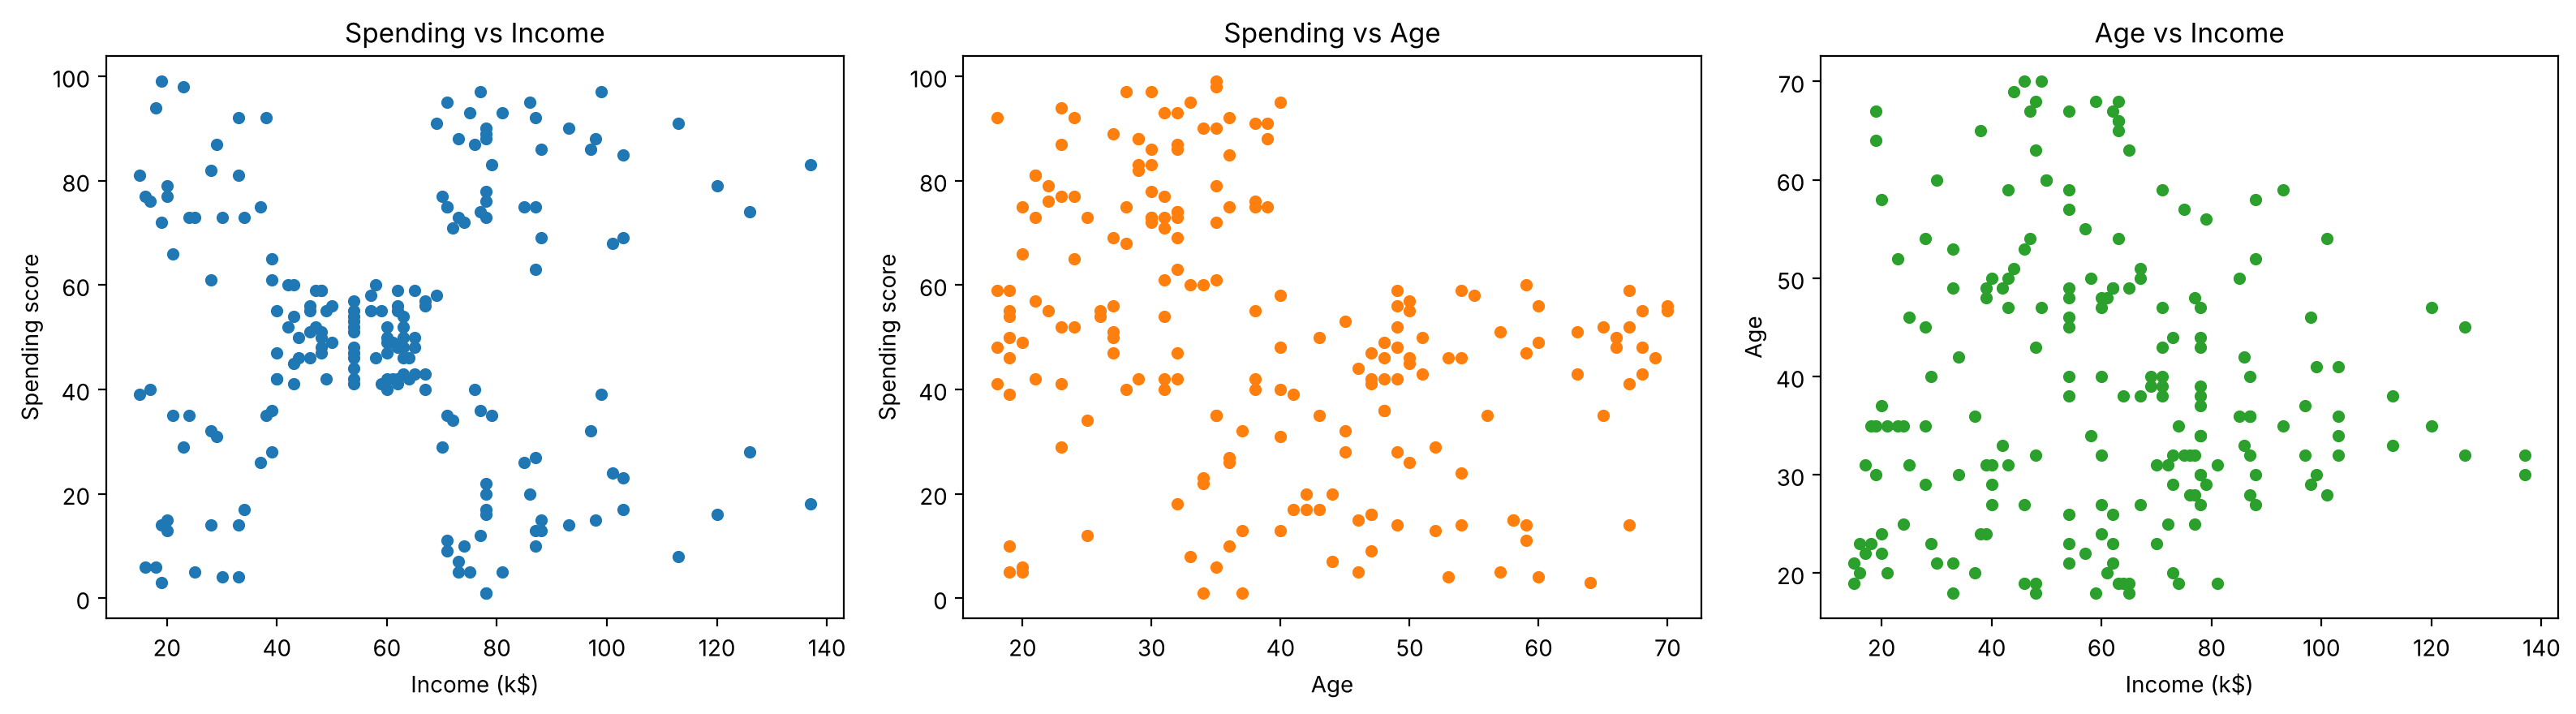

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

ax[0].scatter(df["Income"], df["Spending"], s=20)
ax[0].set_xlabel("Income (k$)")
ax[0].set_ylabel("Spending score")
ax[0].set_title("Spending vs Income")

ax[1].scatter(df["Age"], df["Spending"], s=20, color="tab:orange")
ax[1].set_xlabel("Age")
ax[1].set_ylabel("Spending score")
ax[1].set_title("Spending vs Age")

ax[2].scatter(df["Income"], df["Age"], s=20, color="tab:green")
ax[2].set_xlabel("Income (k$)")
ax[2].set_ylabel("Age")
ax[2].set_title("Age vs Income")

plt.tight_layout()
plt.show()

**(a)** In Spending vs Income I can see 5 groups. There is a tight group in the middle (income about 40 to 70, spending about 40 to 60), and four groups in the corners: low income / high spending, low income / low spending, high income / high spending and high income / low spending. This plot shows the groups most clearly. In Spending vs Age I only see that the high spenders (above 60) are all younger than about 40, but there are no clear separate blobs. Age vs Income is just a cloud, so I cannot see any groups there.

**(b)** There is no target column, so there is no correct answer to compare with. Accuracy needs true labels, and a train/test split only makes sense when we predict a label. Here we can only judge the clusters by distances, silhouette, plots and whether the groups make business sense.

## Part 1 — K-Means From Scratch

### Task 1.1 — Lecture Example 1 in code (one feature)

In [5]:
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
c = np.array([4.0, 11.0])

hist_c = []
hist_sets = []

for it in range(1, 20):
    # distance of every number to both centroids, shape (9, 2)
    d = np.abs(x[:, None] - c[None, :])
    labels = d.argmin(axis=1)
    new_c = np.array([x[labels == k].mean() for k in range(2)])

    print("iteration", it, "| centroids used:", c)
    print("   C1:", x[labels == 0])
    print("   C2:", x[labels == 1])
    print("   new centroids:", new_c)

    hist_c.append(new_c)
    hist_sets.append((set(x[labels == 0]), set(x[labels == 1])))

    if np.allclose(new_c, c):
        print("   no centroid changed, stop")
        break
    c = new_c

inertia = sum(((x[labels == k] - c[k]) ** 2).sum() for k in range(2))
print()
print("final centroids:", c)
print("inertia:", inertia)

iteration 1 | centroids used: [ 4. 11.]
   C1: [2. 4. 3.]
   C2: [10. 12. 20. 30. 11. 25.]
   new centroids: [ 3. 18.]
iteration 2 | centroids used: [ 3. 18.]
   C1: [ 2.  4. 10.  3.]
   C2: [12. 20. 30. 11. 25.]
   new centroids: [ 4.75 19.6 ]
iteration 3 | centroids used: [ 4.75 19.6 ]
   C1: [ 2.  4. 10. 12.  3. 11.]
   C2: [20. 30. 25.]
   new centroids: [ 7. 25.]
iteration 4 | centroids used: [ 7. 25.]
   C1: [ 2.  4. 10. 12.  3. 11.]
   C2: [20. 30. 25.]
   new centroids: [ 7. 25.]
   no centroid changed, stop

final centroids: [ 7. 25.]
inertia: 150.0


In [6]:
# numbers read from lecture slides 9 to 13
slide_c = [[3, 18], [4.75, 19.6], [7, 25], [7, 25]]
slide_sets = [
    ({2, 3, 4}, {10, 11, 12, 20, 25, 30}),
    ({2, 3, 4, 10}, {11, 12, 20, 25, 30}),
    ({2, 3, 4, 10, 11, 12}, {20, 25, 30}),
    ({2, 3, 4, 10, 11, 12}, {20, 25, 30}),
]

check = pd.DataFrame({
    "iteration": [1, 2, 3, 4],
    "my centroids": [list(np.round(h, 2)) for h in hist_c],
    "slide centroids": slide_c,
    "centroids match": [np.allclose(a, b) for a, b in zip(hist_c, slide_c)],
    "clusters match": [a == b for a, b in zip(hist_sets, slide_sets)],
})
print(check.to_string(index=False))
print()
print("final centroids 7 and 25:", np.allclose(c, [7, 25]))
print("inertia 150:", inertia == 150)

 iteration my centroids slide centroids  centroids match  clusters match
         1  [3.0, 18.0]         [3, 18]             True            True
         2 [4.75, 19.6]    [4.75, 19.6]             True            True
         3  [7.0, 25.0]         [7, 25]             True            True
         4  [7.0, 25.0]         [7, 25]             True            True

final centroids 7 and 25: True
inertia 150: True


**Interpretation:** My loop gives exactly the lecture numbers. The centroids after each iteration are (3, 18), (4.75, 19.6), (7, 25) and (7, 25), and the clusters match the slides in every iteration. In iteration 4 nothing moved, so it stops after 4 iterations. The final centroids are 7 and 25 and the inertia is 150 (100 for C1 plus 50 for C2), same as slide 13.

### Task 1.2 — Lecture Example 2 in code (two features)

In [7]:
P = np.array([[185, 72], [170, 56], [168, 60], [179, 68], [182, 72], [188, 77]], dtype=float)
names = ["P1", "P2", "P3", "P4", "P5", "P6"]
c = P[:2].copy()

dist_tables = []

for it in range(1, 20):
    # euclidean distance, shape (6, 2)
    d = np.sqrt(((P[:, None, :] - c[None, :, :]) ** 2).sum(axis=2))
    labels = d.argmin(axis=1)
    new_c = np.array([P[labels == k].mean(axis=0) for k in range(2)])
    dist_tables.append(d)

    print("iteration", it, "| centroids used:", c.tolist())
    table = pd.DataFrame(d.round(2), index=names, columns=["to M1", "to M2"])
    table["cluster"] = ["C" + str(k + 1) for k in labels]
    print(table)
    print("   new centroids:", new_c.tolist())
    print()

    if np.allclose(new_c, c):
        print("no change, stop")
        break
    c = new_c

iteration 1 | centroids used: [[185.0, 72.0], [170.0, 56.0]]
    to M1  to M2 cluster
P1   0.00  21.93      C1
P2  21.93   0.00      C2
P3  20.81   4.47      C2
P4   7.21  15.00      C1
P5   3.00  20.00      C1
P6   5.83  27.66      C1
   new centroids: [[183.5, 72.25], [169.0, 58.0]]

iteration 2 | centroids used: [[183.5, 72.25], [169.0, 58.0]]
    to M1  to M2 cluster
P1   1.52  21.26      C1
P2  21.13   2.24      C2
P3  19.76   2.24      C2
P4   6.19  14.14      C1
P5   1.52  19.10      C1
P6   6.54  26.87      C1
   new centroids: [[183.5, 72.25], [169.0, 58.0]]

no change, stop


In [8]:
# by hand: d(P3, M2) = sqrt((168-170)^2 + (60-56)^2) = sqrt(20)
print("by hand:", round(np.sqrt((168 - 170) ** 2 + (60 - 56) ** 2), 2))
print("from code:", round(dist_tables[0][2, 1], 2))

# slide 15 and slide 16 distance tables
slide_it1 = np.array([[0.00, 21.93], [21.93, 0.00], [20.81, 4.47], [7.21, 15.00], [3.00, 20.00], [5.83, 27.66]])
slide_it2 = np.array([[1.52, 21.26], [21.13, 2.24], [19.76, 2.24], [6.19, 14.14], [1.52, 19.10], [6.54, 26.87]])

print("iteration 1 table matches slide:", np.allclose(dist_tables[0].round(2), slide_it1))
print("iteration 2 table matches slide:", np.allclose(dist_tables[1].round(2), slide_it2))
print("final centroids:", c.tolist(), "(slide: [183.5, 72.25] and [169, 58])")

by hand: 4.47
from code: 4.47
iteration 1 table matches slide: True
iteration 2 table matches slide: True
final centroids: [[183.5, 72.25], [169.0, 58.0]] (slide: [183.5, 72.25] and [169, 58])


**Interpretation:** The distance tables of iteration 1 and iteration 2 are the same as slides 15 and 16 (all values rounded to 2 decimals). My hand check d(P3, M2) = sqrt(2^2 + 4^2) = sqrt(20) = 4.47 agrees with the code. The first iteration gives C1 = P1, P4, P5, P6 and C2 = P2, P3 with new centroids (183.5, 72.25) and (169, 58). In iteration 2 no point switches, so it stops after 2 iterations. C1 is the taller and heavier group and C2 is the shorter and lighter group.

### Task 1.3 — Write your own K-Means function

In [9]:
def my_kmeans(X, init_centroids, max_iter=100, verbose=False):
    X = np.asarray(X, dtype=float)
    C = np.asarray(init_centroids, dtype=float).copy()
    # make 1 feature data 2d so the same code works
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    if C.ndim == 1:
        C = C.reshape(-1, 1)
    K = len(C)

    old_labels = None
    for it in range(1, max_iter + 1):
        # assign step
        d = np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))
        labels = d.argmin(axis=1)

        # update step, an empty cluster keeps its old centroid
        new_C = C.copy()
        for k in range(K):
            if (labels == k).any():
                new_C[k] = X[labels == k].mean(axis=0)

        if verbose:
            print("iteration", it, "labels:", labels, "centroids:", new_C.ravel() if X.shape[1] == 1 else new_C.tolist())

        C = new_C
        # stop when no point changed cluster
        if old_labels is not None and np.array_equal(labels, old_labels):
            break
        old_labels = labels

    inertia = ((X - C[labels]) ** 2).sum()
    return labels, C, inertia, it

In [10]:
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
lab_e1, C_e1, in_e1, it_e1 = my_kmeans(x, [4, 11])

print("labels:", lab_e1)
print("centroids:", C_e1.ravel())
print("inertia:", in_e1)
print("iterations:", it_e1)
print("centroids 7 and 25:", np.allclose(C_e1.ravel(), [7, 25]), "| inertia 150:", np.isclose(in_e1, 150))

labels: [0 0 0 0 0 1 1 0 1]
centroids: [ 7. 25.]
inertia: 150.0
iterations: 4
centroids 7 and 25: True | inertia 150: True


**Interpretation:** `my_kmeans` uses only NumPy (broadcasting for the distances, mean for the update) and no `KMeans()`. On Example 1 it returns centroids 7 and 25, inertia 150 and 4 iterations, which is what the lecture shows. If a cluster becomes empty, the function keeps its old centroid so it does not turn into NaN.

### Task 1.4 — Check your function against scikit-learn

In [11]:
X2 = df[["Income", "Spending"]].values
init5 = X2[:5].astype(float)

my_lab, my_C, my_in, my_it = my_kmeans(X2, init5)

sk = KMeans(n_clusters=5, init=init5, n_init=1, tol=0, algorithm="lloyd").fit(X2)

cmp = pd.DataFrame({
    "my_kmeans": [my_it, round(my_in, 4)],
    "sklearn": [sk.n_iter_, round(sk.inertia_, 4)],
}, index=["iterations", "inertia"])
print(cmp)
print()
print("labels identical:", np.array_equal(my_lab, sk.labels_))
print("centroids close:", np.allclose(my_C, sk.cluster_centers_))
print("largest centroid difference:", np.abs(my_C - sk.cluster_centers_).max())
print()
print(pd.DataFrame(my_C, columns=["Income", "Spending"]).round(2))

             my_kmeans     sklearn
iterations      4.0000      4.0000
inertia     44448.4554  44448.4554

labels identical: True
centroids close: True
largest centroid difference: 2.842170943040401e-14

   Income  Spending
0   26.30     20.91
1   25.73     79.36
2   88.20     17.11
3   86.54     82.13
4   55.30     49.52


**Interpretation:** With the first 5 rows as starting centroids, my function and scikit-learn both take 4 iterations and end with inertia 44448.4554. The labels are identical for all 200 customers and the centroids differ by only about 3e-14, which is floating point rounding. So my implementation matches scikit-learn. The final centroids are the five groups I saw in the scatter plot, for example (88.2, 17.1) for high income / low spending and (26.3, 20.9) for low income / low spending.

### Questions for Part 1

**(a)** At the start the centroids are 4 and 11. Point 10 is only 1 away from 11 but 6 away from 4, so it goes to C2. After iteration 1 the centroids moved to 3 and 18, because C2 had the big values 20, 25 and 30 and its mean went up to 18. Now point 10 is 7 away from 3 and 8 away from 18, so it is closer to C1 and it switches.

**(b)** The loop stops when no point changes its cluster (so the centroids also stop moving). It always stops because both the assign step and the update step can only keep the inertia the same or make it smaller, and there is only a limited number of ways to split the points, so it cannot go on forever. But it stops at the nearest local minimum from the starting centroids, which is not always the best one (Part 3 shows this).

**(c)** Yes. Labels are identical, centroids are the same up to 3e-14 and inertia is 44448.4554 in both, with 4 iterations each. The only small difference is floating point rounding. A real difference could come from empty clusters, because scikit-learn moves an empty centroid to a far point and mine keeps the old one, but this never happened here.

**(d)** A centroid is the average customer of a group, for example (88.2k income, 17.1 spending score) for the high income / low spending group, so it describes what a typical member looks like. The features must be numeric because K-Means needs distances and means, and you cannot subtract or average text like Male/Female.

## Part 2 — Choosing K: Elbow and Silhouette

### Task 2.1 — Elbow and silhouette for K = 2 to 10

In [12]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X2)
    rows.append([k, km.inertia_, silhouette_score(X2, km.labels_)])

res = pd.DataFrame(rows, columns=["K", "Inertia", "Silhouette"])
res.round(4)

,K,Inertia,Silhouette
0,2,181363.5960,0.2969
1,3,106348.3731,0.4676
2,4,73679.7890,0.4932
3,5,44448.4554,0.5539
4,6,37233.8145,0.5398
5,7,30241.3436,0.5288
6,8,25036.4176,0.4548
7,9,21916.7948,0.4561
8,10,20072.0709,0.4411


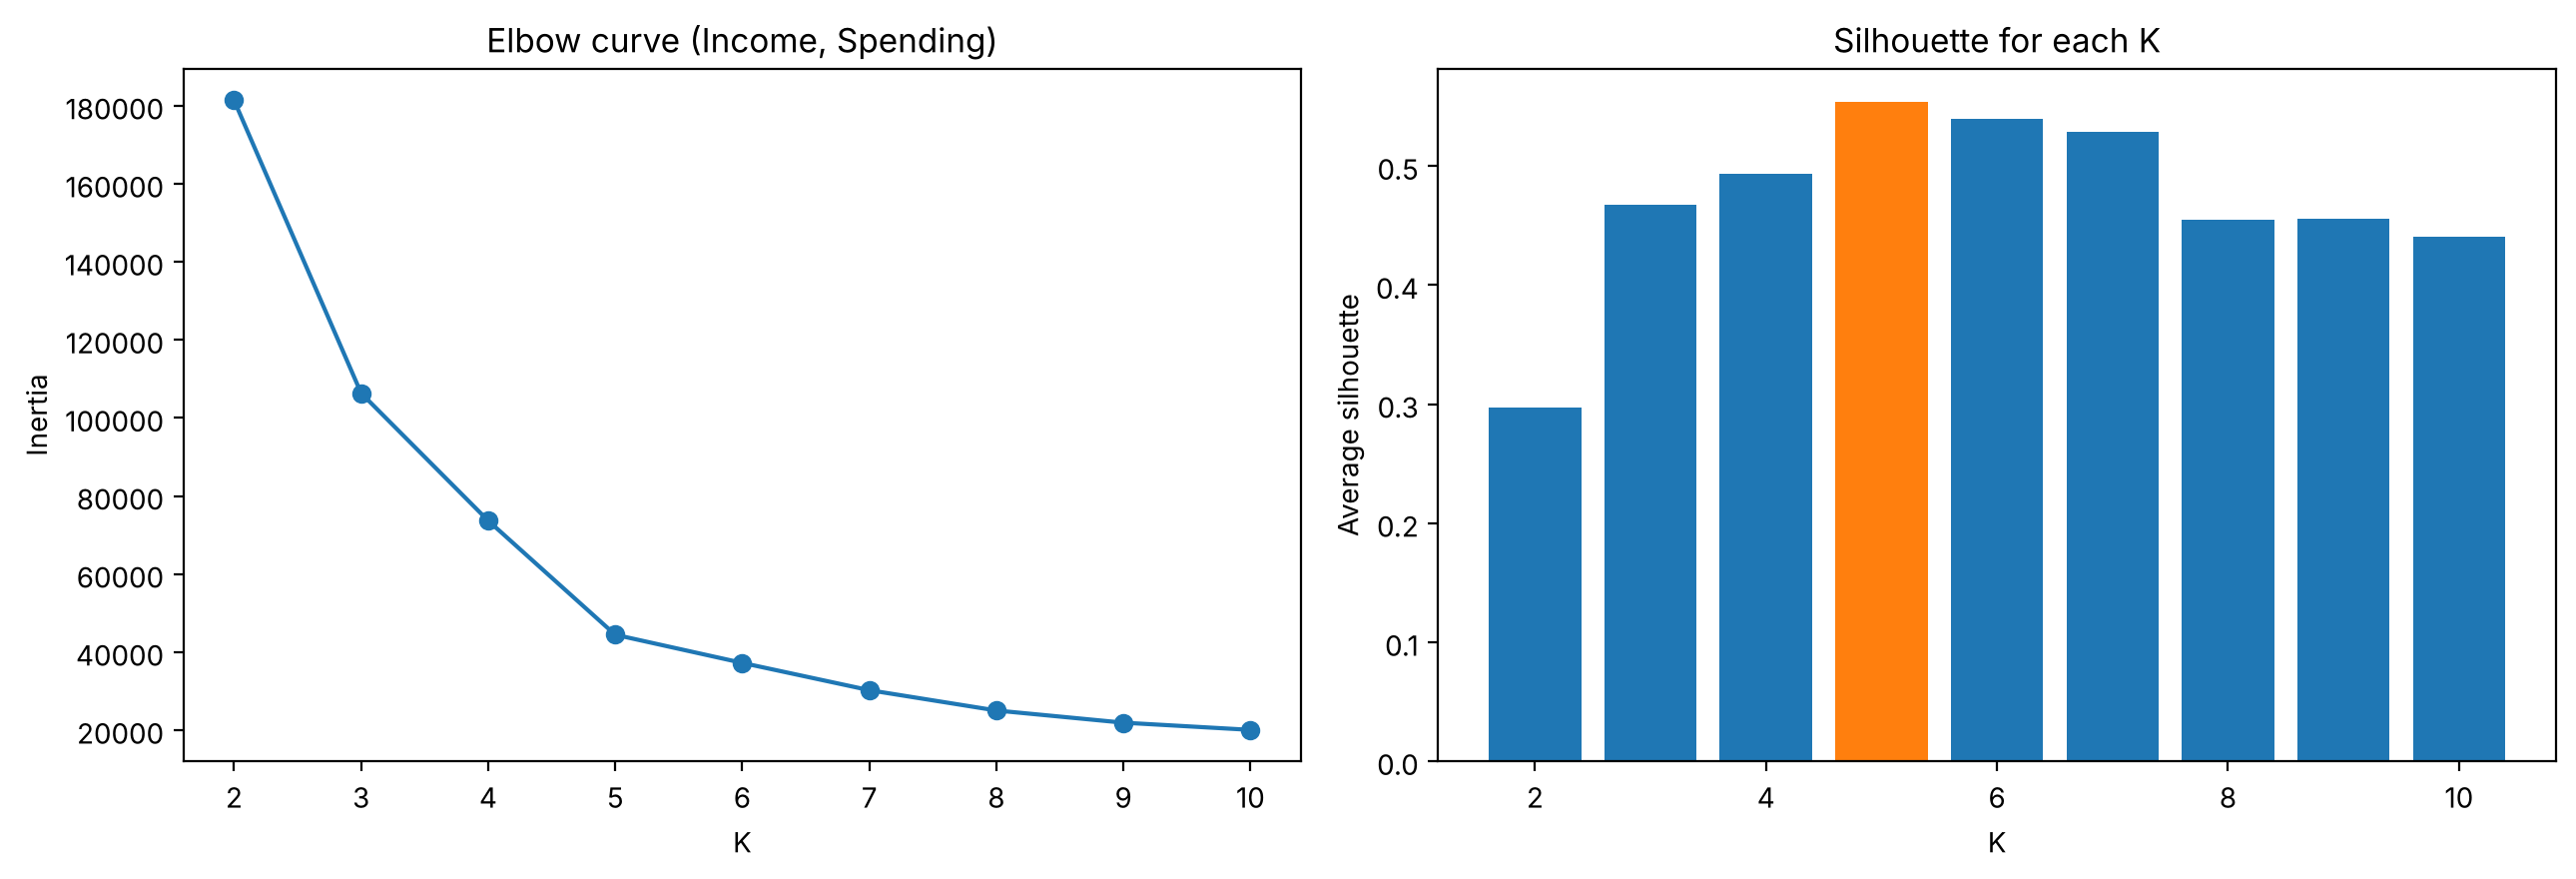

K with the highest silhouette: 5 -> 0.5539


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(res["K"], res["Inertia"], marker="o")
ax[0].set_xlabel("K")
ax[0].set_ylabel("Inertia")
ax[0].set_title("Elbow curve (Income, Spending)")

best_k = int(res.loc[res["Silhouette"].idxmax(), "K"])
bar_colors = ["tab:orange" if k == best_k else "tab:blue" for k in res["K"]]
ax[1].bar(res["K"], res["Silhouette"], color=bar_colors)
ax[1].set_xlabel("K")
ax[1].set_ylabel("Average silhouette")
ax[1].set_title("Silhouette for each K")

plt.tight_layout()
plt.show()

print("K with the highest silhouette:", best_k, "->", round(res["Silhouette"].max(), 4))

In [14]:
# how much inertia falls when K goes up by one
inertia_by_k = res.set_index("K")["Inertia"]
for k in range(3, 9):
    drop = inertia_by_k[k - 1] - inertia_by_k[k]
    print("K", k - 1, "->", k, ": inertia drops by", round(drop), "(", round(100 * drop / inertia_by_k[k - 1], 1), "% )")

K 2 -> 3 : inertia drops by 75015 ( 41.4 % )
K 3 -> 4 : inertia drops by 32669 ( 30.7 % )
K 4 -> 5 : inertia drops by 29231 ( 39.7 % )
K 5 -> 6 : inertia drops by 7215 ( 16.2 % )
K 6 -> 7 : inertia drops by 6992 ( 18.8 % )
K 7 -> 8 : inertia drops by 5205 ( 17.2 % )


**Interpretation:** The inertia keeps falling when K grows (181364 at K=2 down to 20072 at K=10), which is expected. The elbow is at K=5: going from 4 to 5 removes 29231 (39.7%) of the inertia, but going from 5 to 6 only removes 7215 (16.2%), and after that the curve is flat. The silhouette is highest at K=5 with 0.5539 (K=4 gives 0.4932 and K=6 gives 0.5398). Both methods give K=5.

### Task 2.2 — Silhouette by hand

In [15]:
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
lab5 = km5.labels_


def sil_point(X, labels, i):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    # distance from point i to every point
    d = np.sqrt(((X - X[i]) ** 2).sum(axis=1))
    own = labels[i]

    same = labels == own
    same[i] = False
    if same.sum() == 0:
        return 0.0, 0.0, 0.0

    a = d[same].mean()
    b = min(d[labels == k].mean() for k in np.unique(labels) if k != own)
    s = (b - a) / max(a, b)
    return a, b, s


a1, b1, s1 = sil_point(X2, lab5, 0)
sk_s = silhouette_samples(X2, lab5)
print("customer 1 -> a:", round(a1, 3), "b:", round(b1, 3), "s:", round(s1, 4))
print("silhouette_samples gives:", round(sk_s[0], 4), "| same:", np.isclose(s1, sk_s[0]))

customer 1 -> a: 24.64 b: 42.265 s: 0.417
silhouette_samples gives: 0.417 | same: True


In [16]:
# lecture slide 22: Example 1, point x = 10 (a = 4.8, b = 15, s = 0.68)
a_, b_, s_ = sil_point(x, lab_e1, 2)
print("x = 10 -> a:", round(a_, 2), "b:", round(b_, 2), "s:", round(s_, 2))

# my function against sklearn for every customer
mine_all = np.array([sil_point(X2, lab5, i)[2] for i in range(len(X2))])
print("all 200 silhouettes match sklearn:", np.allclose(mine_all, sk_s))

x = 10 -> a: 4.8 b: 15.0 s: 0.68
all 200 silhouettes match sklearn: True


In [17]:
sil_df = pd.DataFrame({"Cluster": lab5, "s": sk_s})
per_cluster = sil_df.groupby("Cluster")["s"].agg(Count="count", Mean="mean", Minimum="min").round(3)
print(per_cluster)
print()
print("customers with negative silhouette:", (sk_s < 0).sum())
print("overall average silhouette:", round(sk_s.mean(), 4))

         Count   Mean  Minimum
Cluster                       
0           81  0.597    0.115
1           39  0.509    0.225
2           22  0.599    0.051
3           35  0.504   -0.023
4           23  0.512   -0.009

customers with negative silhouette: 2
overall average silhouette: 0.5539


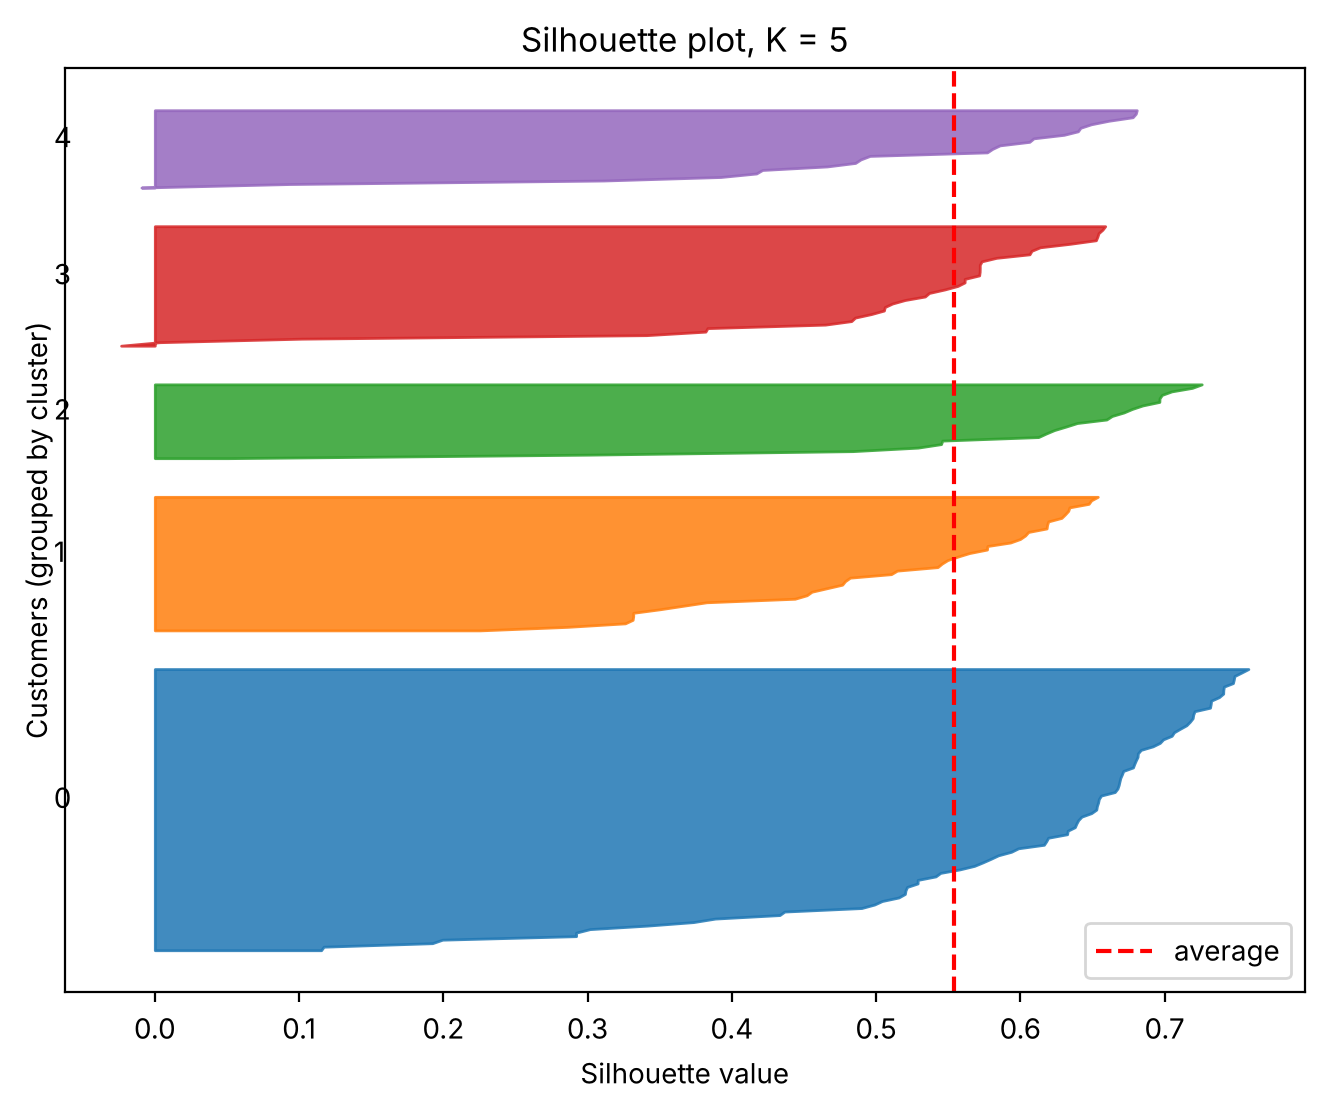

In [18]:
fig, ax = plt.subplots(figsize=(8, 6))
y_low = 10
for k in range(5):
    vals = np.sort(sk_s[lab5 == k])
    y_high = y_low + len(vals)
    ax.fill_betweenx(np.arange(y_low, y_high), 0, vals, color=plt.cm.tab10(k), alpha=0.85)
    ax.text(-0.07, y_low + len(vals) / 2, str(k))
    y_low = y_high + 10

ax.axvline(sk_s.mean(), color="red", linestyle="--", label="average")
ax.set_xlabel("Silhouette value")
ax.set_ylabel("Customers (grouped by cluster)")
ax.set_title("Silhouette plot, K = 5")
ax.set_yticks([])
ax.legend()
plt.show()

**Interpretation:** For customer 1 (row 0) my function gives a = 24.64, b = 42.27 and s = 0.417, and `silhouette_samples` gives the same value. My function also reproduces the lecture example: for x = 10 I get a = 4.8, b = 15 and s = 0.68, as on slide 22, and all 200 silhouette values match scikit-learn. The cluster means are between 0.504 and 0.599, so the clusters are all reasonably good. Cluster 3 (high income / low spending) has the weakest average (0.504) and a minimum of -0.023. Only 2 customers have a negative silhouette (one in cluster 3 and one in cluster 4), and both are very close to 0, so they are on the border and not clearly in the wrong cluster. In the silhouette plot almost everything is to the right of 0, and only the bottom tips of cluster 3 and cluster 4 go slightly below 0. Clusters 0 and 2 reach the highest values (about 0.75 and 0.73), and cluster 3 has the largest part of its block under the average line (the red dashed line at 0.554).

### Task 2.3 — The lecture practice problem

In [19]:
pts = np.array([1, 3, 5, 7, 11, 13, 15], dtype=float).reshape(-1, 1)
lab_p, C_p, in_p, it_p = my_kmeans(pts, [1, 11], verbose=True)

print()
print("cluster 1:", pts[lab_p == 0].ravel(), "centroid", C_p[0, 0])
print("cluster 2:", pts[lab_p == 1].ravel(), "centroid", C_p[1, 0])
print("iterations:", it_p, "| inertia:", in_p)

iteration 1 labels: [0 0 0 1 1 1 1] centroids: [ 3.  11.5]
iteration 2 labels: [0 0 0 0 1 1 1] centroids: [ 4. 13.]
iteration 3 labels: [0 0 0 0 1 1 1] centroids: [ 4. 13.]

cluster 1: [1. 3. 5. 7.] centroid 4.0
cluster 2: [11. 13. 15.] centroid 13.0
iterations: 3 | inertia: 28.0


In [20]:
sk_p = silhouette_samples(pts, lab_p)
rows = []
for value in [1, 7, 11]:
    i = int(np.where(pts.ravel() == value)[0][0])
    a, b, s = sil_point(pts, lab_p, i)
    rows.append([value, round(a, 3), round(b, 3), round(s, 3), round(sk_p[i], 3)])

print(pd.DataFrame(rows, columns=["point", "a", "b", "s (mine)", "s (sklearn)"]).to_string(index=False))

 point   a    b  s (mine)  s (sklearn)
     1 4.0 12.0     0.667        0.667
     7 4.0  6.0     0.333        0.333
    11 3.0  7.0     0.571        0.571


**Interpretation:** The practice problem takes 3 iterations. Iteration 1 gives C1 = {1, 3, 5} and C2 = {7, 11, 13, 15} with centroids 3 and 11.5. In iteration 2 point 7 moves to C1, because |7-3| = 4 is smaller than |7-11.5| = 4.5, giving centroids 4 and 13. Iteration 3 has no change. Final: C1 = {1, 3, 5, 7} with centroid 4, C2 = {11, 13, 15} with centroid 13, inertia 28. Silhouette values by hand match `silhouette_samples`: point 1 has a = 4, b = 12, s = 0.667; point 7 has a = 4, b = 6, s = 0.333; point 11 has a = 3, b = 7, s = 0.571 (bonus).

### Questions for Part 2

**(a)** The elbow suggests K=5: inertia drops by 29231 from K=4 to 5 but only by 7215 from K=5 to 6. The silhouette also suggests K=5 (0.5539, compared with 0.4932 for K=4 and 0.5398 for K=6). They agree.

**(b)** Customer 1 has s = 0.417 (a = 24.64, b = 42.27). It is positive, so he is in the right cluster, but it is lower than the average of 0.554 because he is at the edge of his group (Income 15, Spending 39). The weakest cluster on average is cluster 3 (mean 0.504). 2 customers have a negative silhouette.

**(c)** Point 7 is less well placed. Point 1 has a = 4 and b = 12 (s = 0.667), but point 7 has the same a = 4 and only b = 6 (s = 0.333). Point 7 is at the edge of its cluster, close to the other cluster, so the gap between a and b is small.

**(d)** Inertia always goes down when K goes up, and with K = 200 every customer is its own cluster and the inertia is 0. So the lowest inertia would always pick the biggest K, which is useless. We need the bend of the elbow, the silhouette, and whether the groups make sense for the business.

## Part 3 — Starting Points and Stability

### Task 3.1 — 30 different seeds

In [21]:
settings = {
    "random, n_init=1": dict(init="random", n_init=1),
    "k-means++, n_init=1": dict(init="k-means++", n_init=1),
    "k-means++, n_init=10": dict(init="k-means++", n_init=10),
}

runs = {}
for name, kw in settings.items():
    runs[name] = []
    for seed in range(30):
        km = KMeans(n_clusters=5, random_state=seed, **kw).fit(X2)
        runs[name].append((km.inertia_, km.labels_, km.cluster_centers_))

best_overall = min(r[0] for rs in runs.values() for r in rs)
print("best inertia in all 90 runs:", round(best_overall, 1))

rows = []
for name, rs in runs.items():
    vals = np.array([r[0] for r in rs])
    reached = np.isclose(vals.round(1), round(best_overall, 1))
    rows.append([name, len(np.unique(vals.round(1))), vals.min().round(1), vals.max().round(1), round(100 * reached.mean(), 1)])

stab = pd.DataFrame(rows, columns=["setting", "distinct inertias", "lowest", "highest", "% runs at best"])
stab

best inertia in all 90 runs: 44448.5


,setting,distinct inertias,lowest,highest,% runs at best
0,"random, n_init=1",14,44448.5,91762.0,33.3
1,"k-means++, n_init=1",6,44448.5,66733.4,60.0
2,"k-means++, n_init=10",1,44448.5,44448.5,100.0


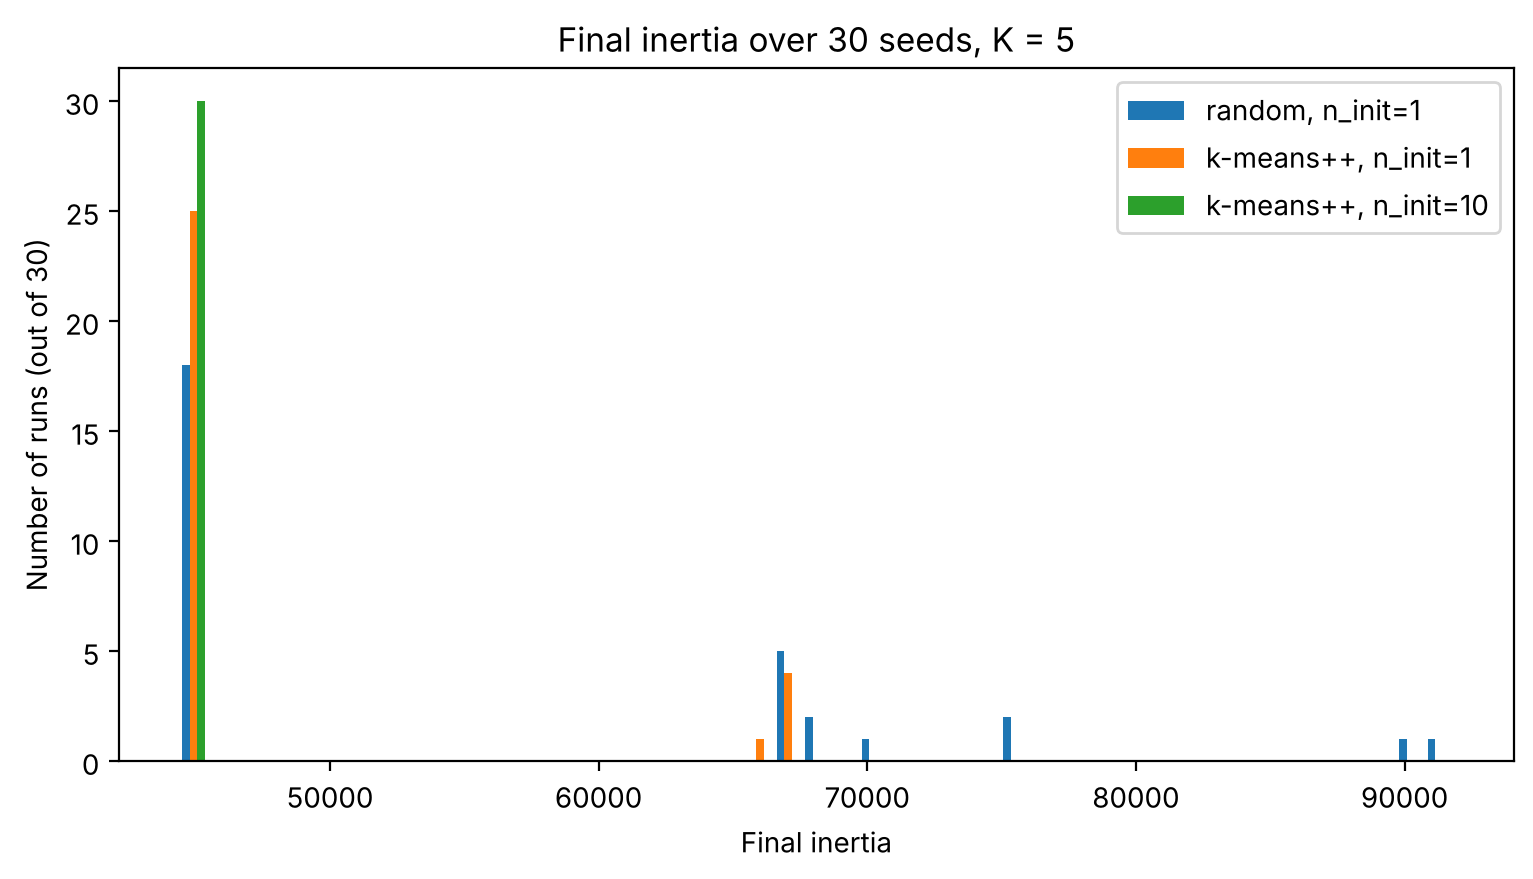

In [22]:
plt.figure(figsize=(9, 4.5))
all_vals = [[r[0] for r in rs] for rs in runs.values()]
edges = np.linspace(min(map(min, all_vals)) - 50, max(map(max, all_vals)) + 50, 46)
plt.hist(all_vals, bins=edges, label=list(runs.keys()))
plt.xlabel("Final inertia")
plt.ylabel("Number of runs (out of 30)")
plt.title("Final inertia over 30 seeds, K = 5")
plt.legend()
plt.show()

**Interpretation:** The best inertia in all 90 runs is 44448.5. With `init='random'` and n_init=1 the 30 runs gave 14 different inertia values, from 44448.5 up to 91762.0, and only 33.3% of the runs (10 of 30) reached the best one. With k-means++ and n_init=1 there were 6 different values (highest 66733.4) and 60.0% reached the best. With k-means++ and n_init=10 there was only 1 value and 100% of the runs reached 44448.5. In the histogram the n_init=10 bars are all at the best value, while the random-start bars are spread out, with some runs at 67000 and some near 90000.

### Task 3.2 — Best run vs worst run

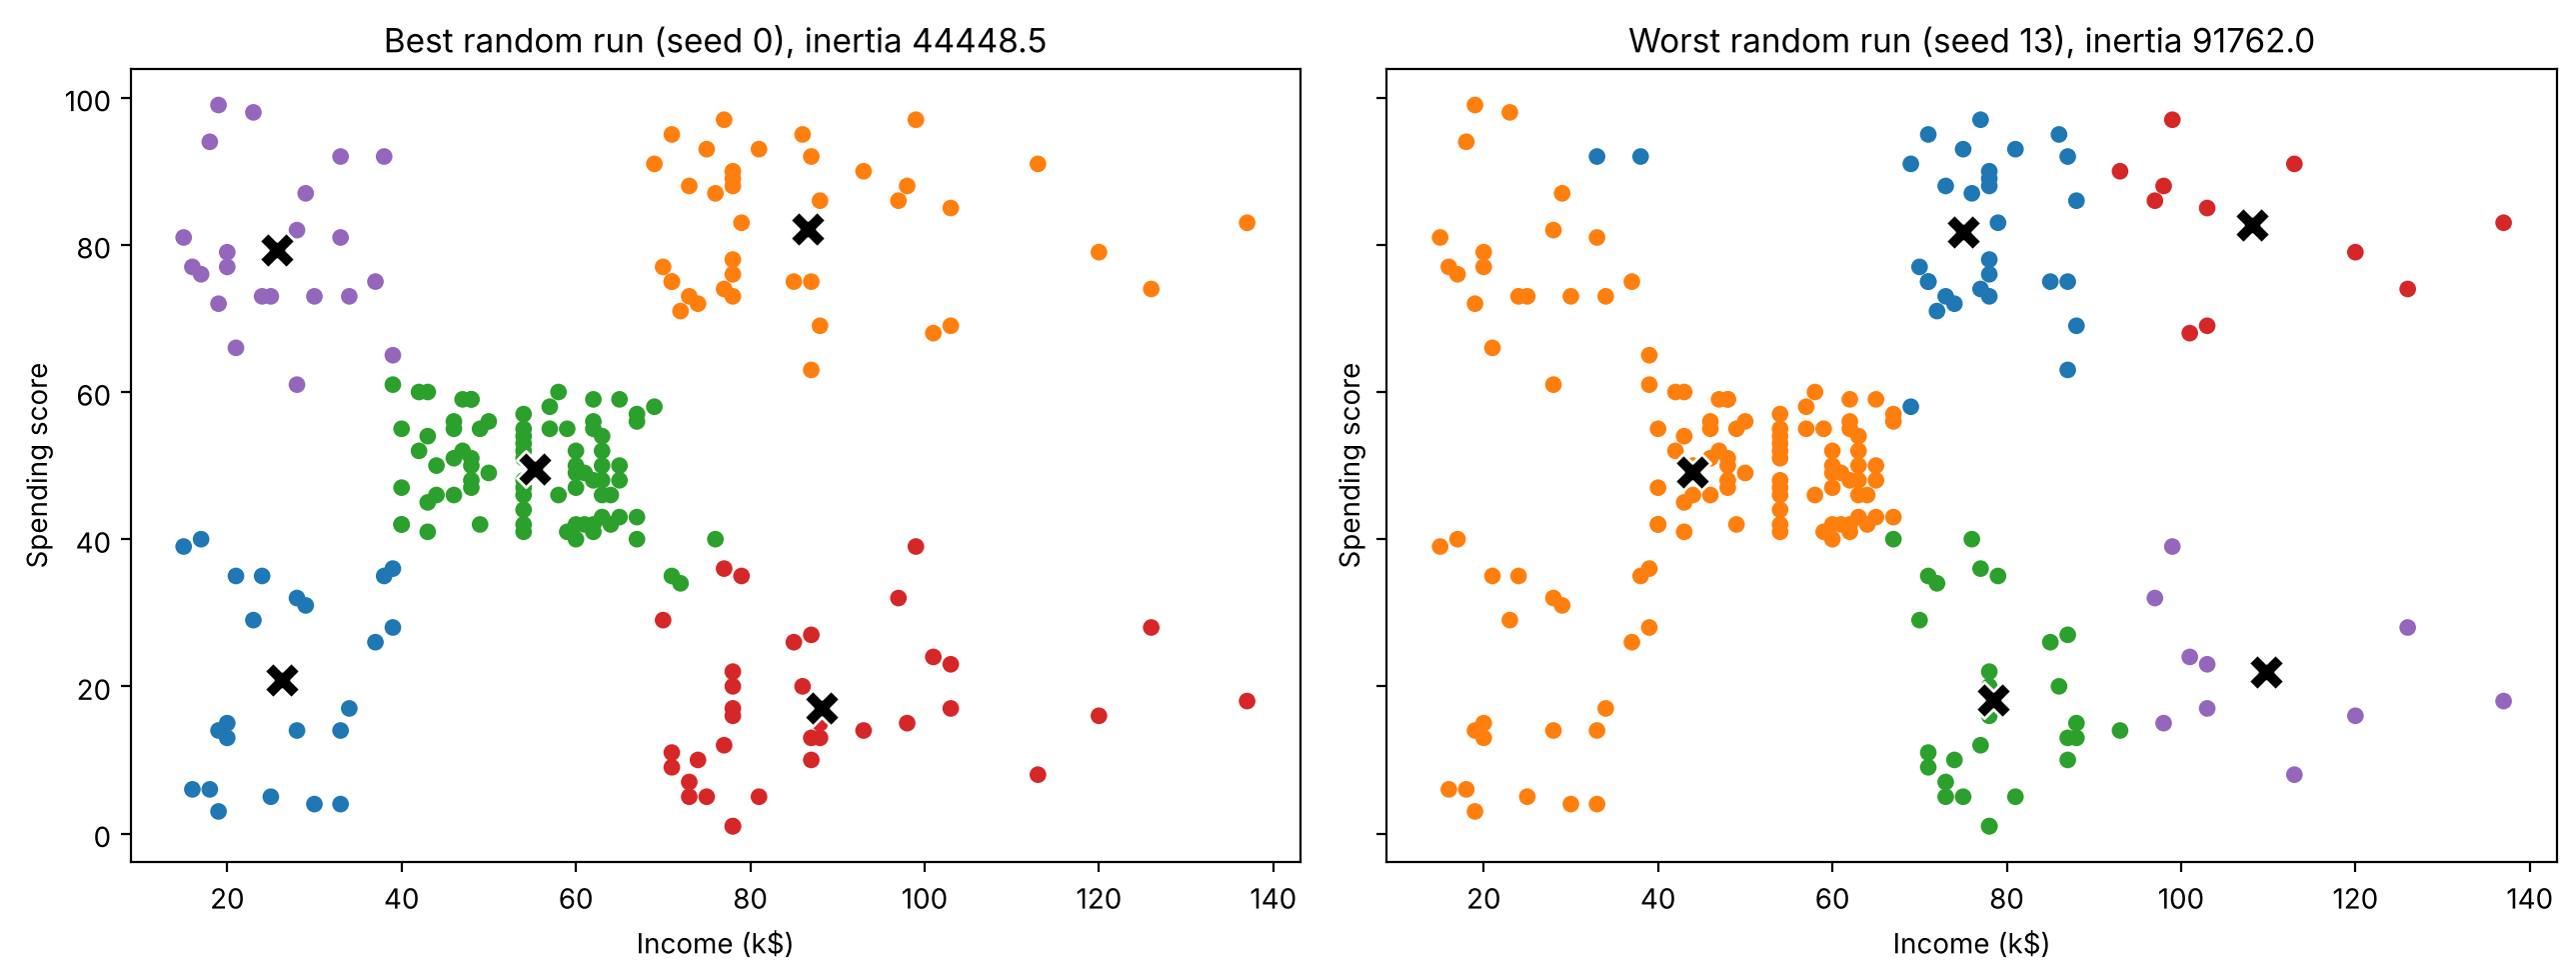

best inertia : 44448.5
worst inertia: 91762.0
ARI best vs worst: 0.4553


In [23]:
rand_runs = runs["random, n_init=1"]
i_best = int(np.argmin([r[0] for r in rand_runs]))
i_worst = int(np.argmax([r[0] for r in rand_runs]))
best_run = rand_runs[i_best]
worst_run = rand_runs[i_worst]

fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for a, run, title in [(ax[0], best_run, "Best random run (seed " + str(i_best) + ")"),
                      (ax[1], worst_run, "Worst random run (seed " + str(i_worst) + ")")]:
    a.scatter(X2[:, 0], X2[:, 1], c=run[1], cmap="tab10", vmin=0, vmax=9, s=25)
    a.scatter(run[2][:, 0], run[2][:, 1], c="black", marker="X", s=170, edgecolor="white")
    a.set_title(title + ", inertia " + str(round(run[0], 1)))
    a.set_xlabel("Income (k$)")
    a.set_ylabel("Spending score")
plt.tight_layout()
plt.show()

print("best inertia :", round(best_run[0], 1))
print("worst inertia:", round(worst_run[0], 1))
print("ARI best vs worst:", round(adjusted_rand_score(best_run[1], worst_run[1]), 4))

**Interpretation:** The best random run (seed 0) has inertia 44448.5 and shows the 5 clear groups. The worst one (seed 13) has inertia 91762.0, which is more than 2 times higher. In the picture one centroid (at about income 44, spending 49) has to cover the whole left side, so the low income / low spending, low income / high spending and middle groups are all in one cluster, while the high income side is cut into 4 pieces: the high spending group is split into two clusters (centroids at about income 75 and 108) and the low spending group is split into two as well. Their ARI is only 0.4553, so the two answers are really different groupings, not just different numbers.

### Questions for Part 3

**(a)** Random start gave 14 different final inertia values and only 33.3% of its runs reached the best. k-means++ with n_init=1 gave 6 values and 60.0%, and k-means++ with n_init=10 gave 1 value and 100%.

**(b)** The assign/update loop only goes down to the nearest local minimum from where it started. If the starting centroids are bad (for example two of them start in the same group), the loop is stuck in a worse solution, so same data and same K can give different answers.

**(c)** k-means++ chooses starting centroids that are far from each other, so it rarely puts two starts in the same group (60.0% vs 33.3% at the best value). n_init=10 runs 10 different starts and keeps the one with the lowest inertia, and in my table it gave 44448.5 for all 30 seeds. The cost is that it takes about 10 times longer.

**(d)** Cluster numbers are only names. The same grouping can be called 0,1,2 in one run and 2,0,1 in another, so comparing labels directly would say they are different. ARI compares pairs of points (are they together or not), so it does not depend on the numbers. For example the best and worst runs have ARI = 0.4553, which is a real difference.

## Part 4 — Scaling: Units Decide the Clusters

### Task 4.1 — Change the unit, change the clusters

In [24]:
age_inc_k = df[["Age", "Income"]].values.astype(float)
age_inc_d = age_inc_k.copy()
age_inc_d[:, 1] = age_inc_d[:, 1] * 1000

versions = {
    "raw k$": age_inc_k,
    "raw dollars": age_inc_d,
    "scaled k$": StandardScaler().fit_transform(age_inc_k),
    "scaled dollars": StandardScaler().fit_transform(age_inc_d),
}

lab4 = {}
for name, Xv in versions.items():
    lab4[name] = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(Xv)
    print(name.ljust(15), "cluster sizes:", np.bincount(lab4[name]))

raw k$          cluster sizes: [56 73 47 24]
raw dollars     cluster sizes: [50 62 68 20]
scaled k$       cluster sizes: [60 62 43 35]
scaled dollars  cluster sizes: [60 62 43 35]


In [25]:
# is raw dollars basically a clustering on Income alone?
inc_only = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(df[["Income"]].values * 1000.0)
print("raw dollars vs Income-only clusters -> ARI =", round(adjusted_rand_score(lab4["raw dollars"], inc_only), 4))
print("raw k$ vs Income-only clusters      -> ARI =", round(adjusted_rand_score(lab4["raw k$"], inc_only), 4))

raw dollars vs Income-only clusters -> ARI = 1.0
raw k$ vs Income-only clusters      -> ARI = 0.4897


In [26]:
pairs = [("raw k$", "raw dollars"), ("scaled k$", "scaled dollars"), ("raw dollars", "scaled dollars")]
for p, q in pairs:
    print(p, "vs", q, "-> ARI =", round(adjusted_rand_score(lab4[p], lab4[q]), 4))

raw k$ vs raw dollars -> ARI = 0.4897
scaled k$ vs scaled dollars -> ARI = 1.0
raw dollars vs scaled dollars -> ARI = 0.3605


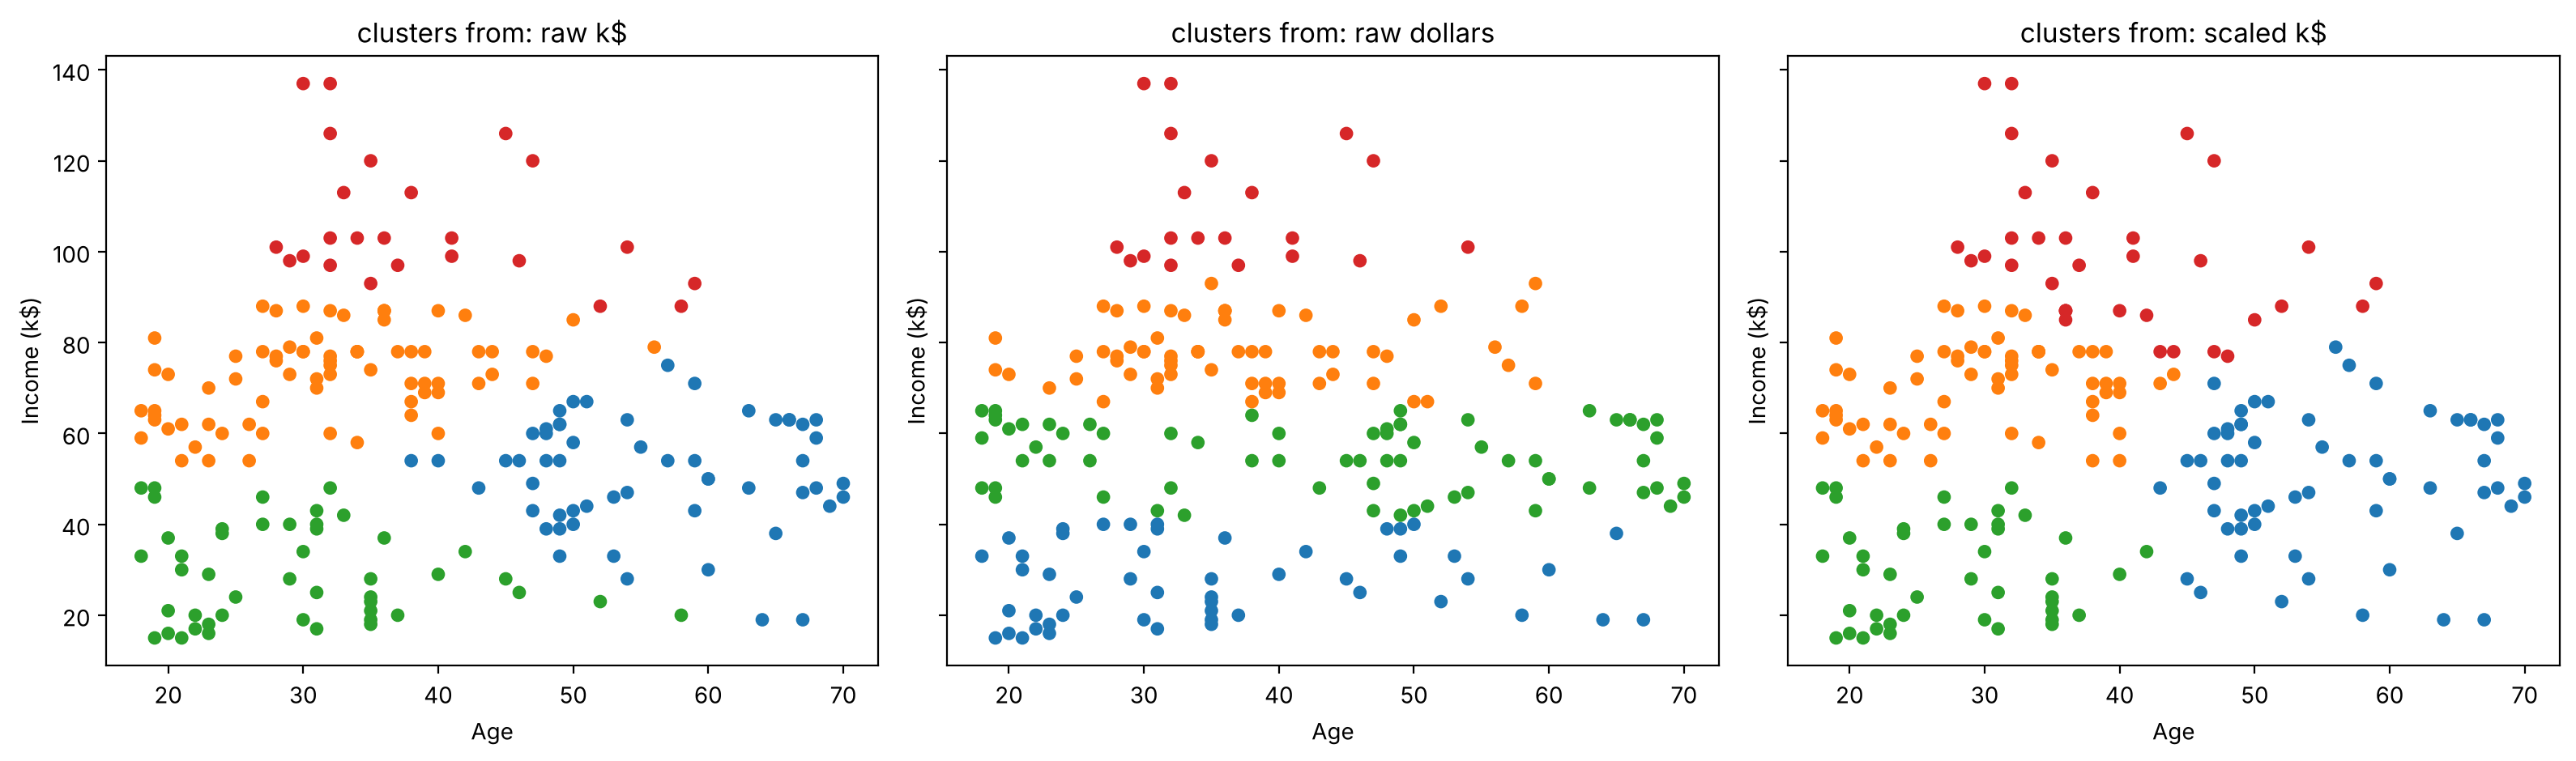

In [27]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
for a, name in zip(ax, ["raw k$", "raw dollars", "scaled k$"]):
    a.scatter(df["Age"], df["Income"], c=lab4[name], cmap="tab10", vmin=0, vmax=9, s=25)
    a.set_title("clusters from: " + name)
    a.set_xlabel("Age")
    a.set_ylabel("Income (k$)")
plt.tight_layout()
plt.show()

**Interpretation:** Just changing Income from k$ to dollars changes the clusters: the sizes go from [56, 73, 47, 24] to [50, 62, 68, 20] and the ARI between them is only 0.4897. The raw dollar clustering is exactly the same as clustering on Income alone (ARI = 1.0). After StandardScaler the k$ and dollars versions are identical (ARI = 1.0, same sizes [60, 62, 43, 35]), because scaling removes the unit. The ARI between raw dollars and scaled dollars is only 0.3605. In the three plots the raw dollars clusters are horizontal bands of income and Age plays no role, while the scaled clusters use both Age and Income.

### Task 4.2 — Wine data: raw vs scaled

In [28]:
wine = load_wine()
Xw = pd.DataFrame(wine.data, columns=wine.feature_names)
yw = wine.target
print("shape:", Xw.shape, "| true cultivar counts:", np.bincount(yw))

sd = Xw.std().sort_values(ascending=False)
print()
print("three largest standard deviations:")
print(sd.head(3).round(3))
print()
print("smallest standard deviation:")
print(sd.tail(1).round(3))
print()
print("largest / smallest ratio:", round(sd.iloc[0] / sd.iloc[-1]))

shape: (178, 13) | true cultivar counts: [59 71 48]

three largest standard deviations:
proline              314.907
magnesium             14.282
alcalinity_of_ash      3.340
dtype: float64

smallest standard deviation:
nonflavanoid_phenols    0.124
dtype: float64

largest / smallest ratio: 2530


In [29]:
Xw_scaled = StandardScaler().fit_transform(Xw)

km_raw = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xw)
km_sc = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xw_scaled)

wine_res = pd.DataFrame({
    "ARI vs true cultivar": [adjusted_rand_score(yw, km_raw.labels_), adjusted_rand_score(yw, km_sc.labels_)],
    "silhouette": [silhouette_score(Xw, km_raw.labels_), silhouette_score(Xw_scaled, km_sc.labels_)],
    "cluster sizes": [np.bincount(km_raw.labels_).tolist(), np.bincount(km_sc.labels_).tolist()],
}, index=["raw", "scaled"])
wine_res["ARI vs true cultivar"] = wine_res["ARI vs true cultivar"].round(4)
wine_res["silhouette"] = wine_res["silhouette"].round(4)
wine_res

,ARI vs true cultivar,silhouette,cluster sizes
raw,0.3711,0.5711,"[62, 47, 69]"
scaled,0.8975,0.2849,"[65, 51, 62]"


In [30]:
# is the raw clustering just proline?
prol = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(Xw[["proline"]].values)
print("raw clusters vs proline-only clusters -> ARI =", round(adjusted_rand_score(km_raw.labels_, prol), 4))
print("scaled clusters vs proline-only clusters -> ARI =", round(adjusted_rand_score(km_sc.labels_, prol), 4))

raw clusters vs proline-only clusters -> ARI = 1.0
scaled clusters vs proline-only clusters -> ARI = 0.3543


**Interpretation:** The largest standard deviations in Wine are proline (314.9), magnesium (14.3) and alcalinity of ash (3.34), and the smallest is nonflavanoid phenols (0.124), so proline is about 2530 times bigger than the smallest. The raw clustering is exactly the same as clustering on proline alone (ARI = 1.0), so the other 12 features did nothing. Results against the true cultivars: raw data has ARI 0.3711, silhouette 0.5711 and sizes [62, 47, 69]; scaled data has ARI 0.8975, silhouette 0.2849 and sizes [65, 51, 62]. The true sizes are [59, 71, 48], so the scaled result is much closer.

### Task 4.3 — Draw it

variance explained by the 2 components: [0.362 0.192] total 0.554


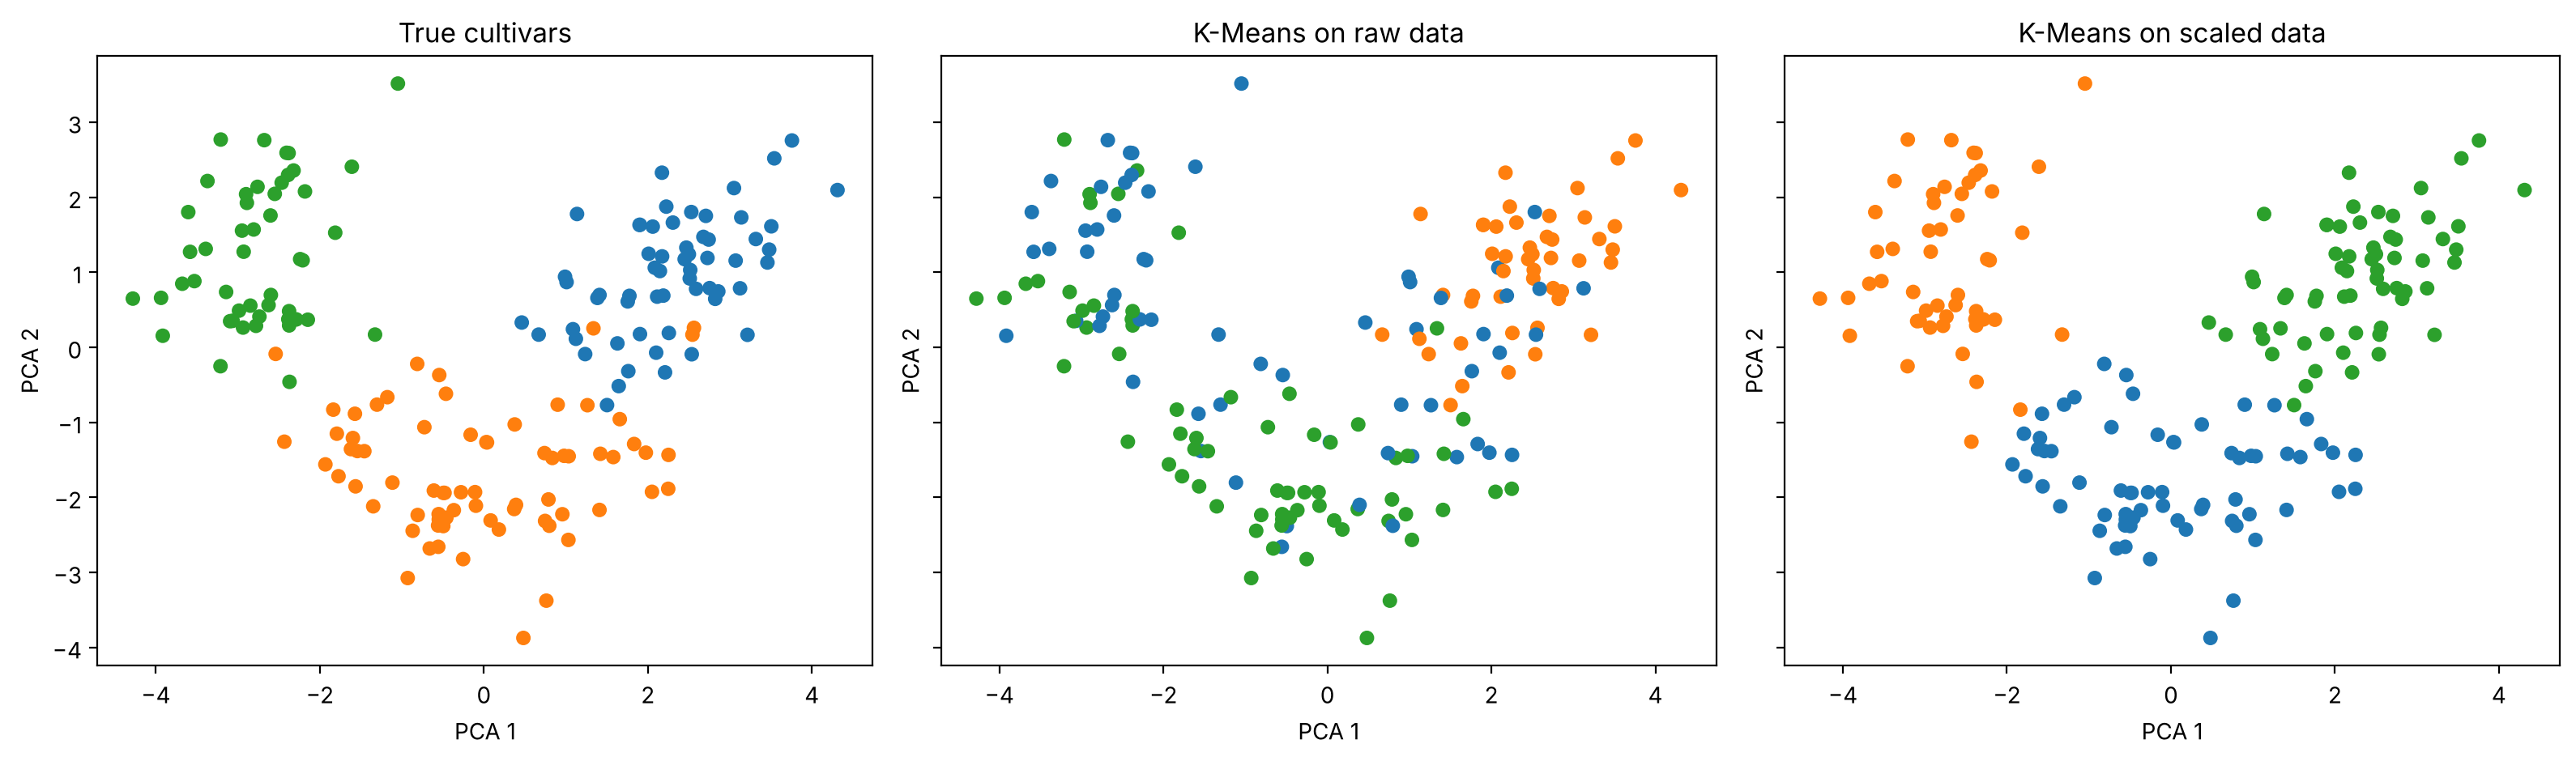

In [31]:
pca = PCA(n_components=2)
Z = pca.fit_transform(Xw_scaled)
print("variance explained by the 2 components:", pca.explained_variance_ratio_.round(3), "total", pca.explained_variance_ratio_.sum().round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
panels = [(yw, "True cultivars"), (km_raw.labels_, "K-Means on raw data"), (km_sc.labels_, "K-Means on scaled data")]
for a, (lab, title) in zip(ax, panels):
    a.scatter(Z[:, 0], Z[:, 1], c=lab, cmap="tab10", vmin=0, vmax=9, s=30)
    a.set_title(title)
    a.set_xlabel("PCA 1")
    a.set_ylabel("PCA 2")
plt.tight_layout()
plt.show()

**Interpretation:** The cluster colours are arbitrary in each panel, only the shapes matter. In the true cultivars panel there are three groups (top left, bottom middle, top right). The scaled K-Means panel finds almost the same three groups, with only a few points near the borders being different. The raw K-Means panel is wrong: it splits the points by proline level, so the left group is mixed with the middle one and the bottom group is divided between two clusters. This matches ARI 0.8975 for scaled vs 0.3711 for raw. (The PCA plot shows 55.4% of the variance, so it is only a rough picture.)

### Questions for Part 4

**(a)** The distance is sqrt(ΔAge^2 + ΔIncome^2). When Income is in dollars, ΔIncome can be up to 122,000 while ΔAge is at most 52, so the Age part is almost zero and the distance is basically |ΔIncome|. That is why the dollar clustering is the same as an Income-only clustering (ARI = 1.0) and differs from the k$ clustering (ARI = 0.4897). So the unit decides which feature controls the distance. After scaling both versions are identical (ARI = 1.0).

**(b)** Proline dominated the raw distance. Its standard deviation is 314.9 against 14.3 for magnesium, 3.34 for alcalinity of ash and 0.124 for the smallest feature. The raw clustering equals the proline-only clustering (ARI = 1.0). Against the true cultivar the raw ARI was 0.3711 and the scaled ARI was 0.8975.

**(c)** The silhouette is calculated with the same distance as the clustering. In the raw space the data is mainly one long proline axis, so the points form clean bands and the silhouette looks good (0.5711), but those bands are not the real cultivars. In the scaled space all 13 features count, the groups overlap more, so the silhouette is lower (0.2849) even though the result is better (ARI 0.8975). The silhouette does not know the truth. Comparing it between raw and scaled is not fair because the two are in different spaces with different distances.

**(d)** I will scale when the features have different units or very different standard deviations, which I check first with `describe()` or `std()`. I will only skip scaling if all features have the same unit and scale and a bigger range really should count more.

## Part 5 — Outliers and Anomalies

### Task 5.1 — One extreme customer

In [32]:
extra = np.array([[400, 99]])
X_out = np.vstack([X2, extra])

km_base = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
km_out = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X_out)


def summary(model, X):
    cen = model.cluster_centers_
    order = np.argsort(cen[:, 0])
    out = pd.DataFrame({
        "Income": cen[order, 0],
        "Spending": cen[order, 1],
        "size": np.bincount(model.labels_, minlength=5)[order],
    })
    return out.round(1).reset_index(drop=True)


print("WITHOUT the extra customer (200 rows)")
print(summary(km_base, X2))
print()
print("WITH the extra customer (201 rows)")
print(summary(km_out, X_out))
print()
print("ARI on the original 200 customers:", round(adjusted_rand_score(km_base.labels_, km_out.labels_[:200]), 4))

WITHOUT the extra customer (200 rows)
   Income  Spending  size
0    25.7      79.4    22
1    26.3      20.9    23
2    55.3      49.5    81
3    86.5      82.1    39
4    88.2      17.1    35

WITH the extra customer (201 rows)
   Income  Spending  size
0    26.3      20.9    23
1    48.3      56.5   100
2    86.5      82.1    39
3    87.0      18.6    38
4   400.0      99.0     1

ARI on the original 200 customers: 0.7532


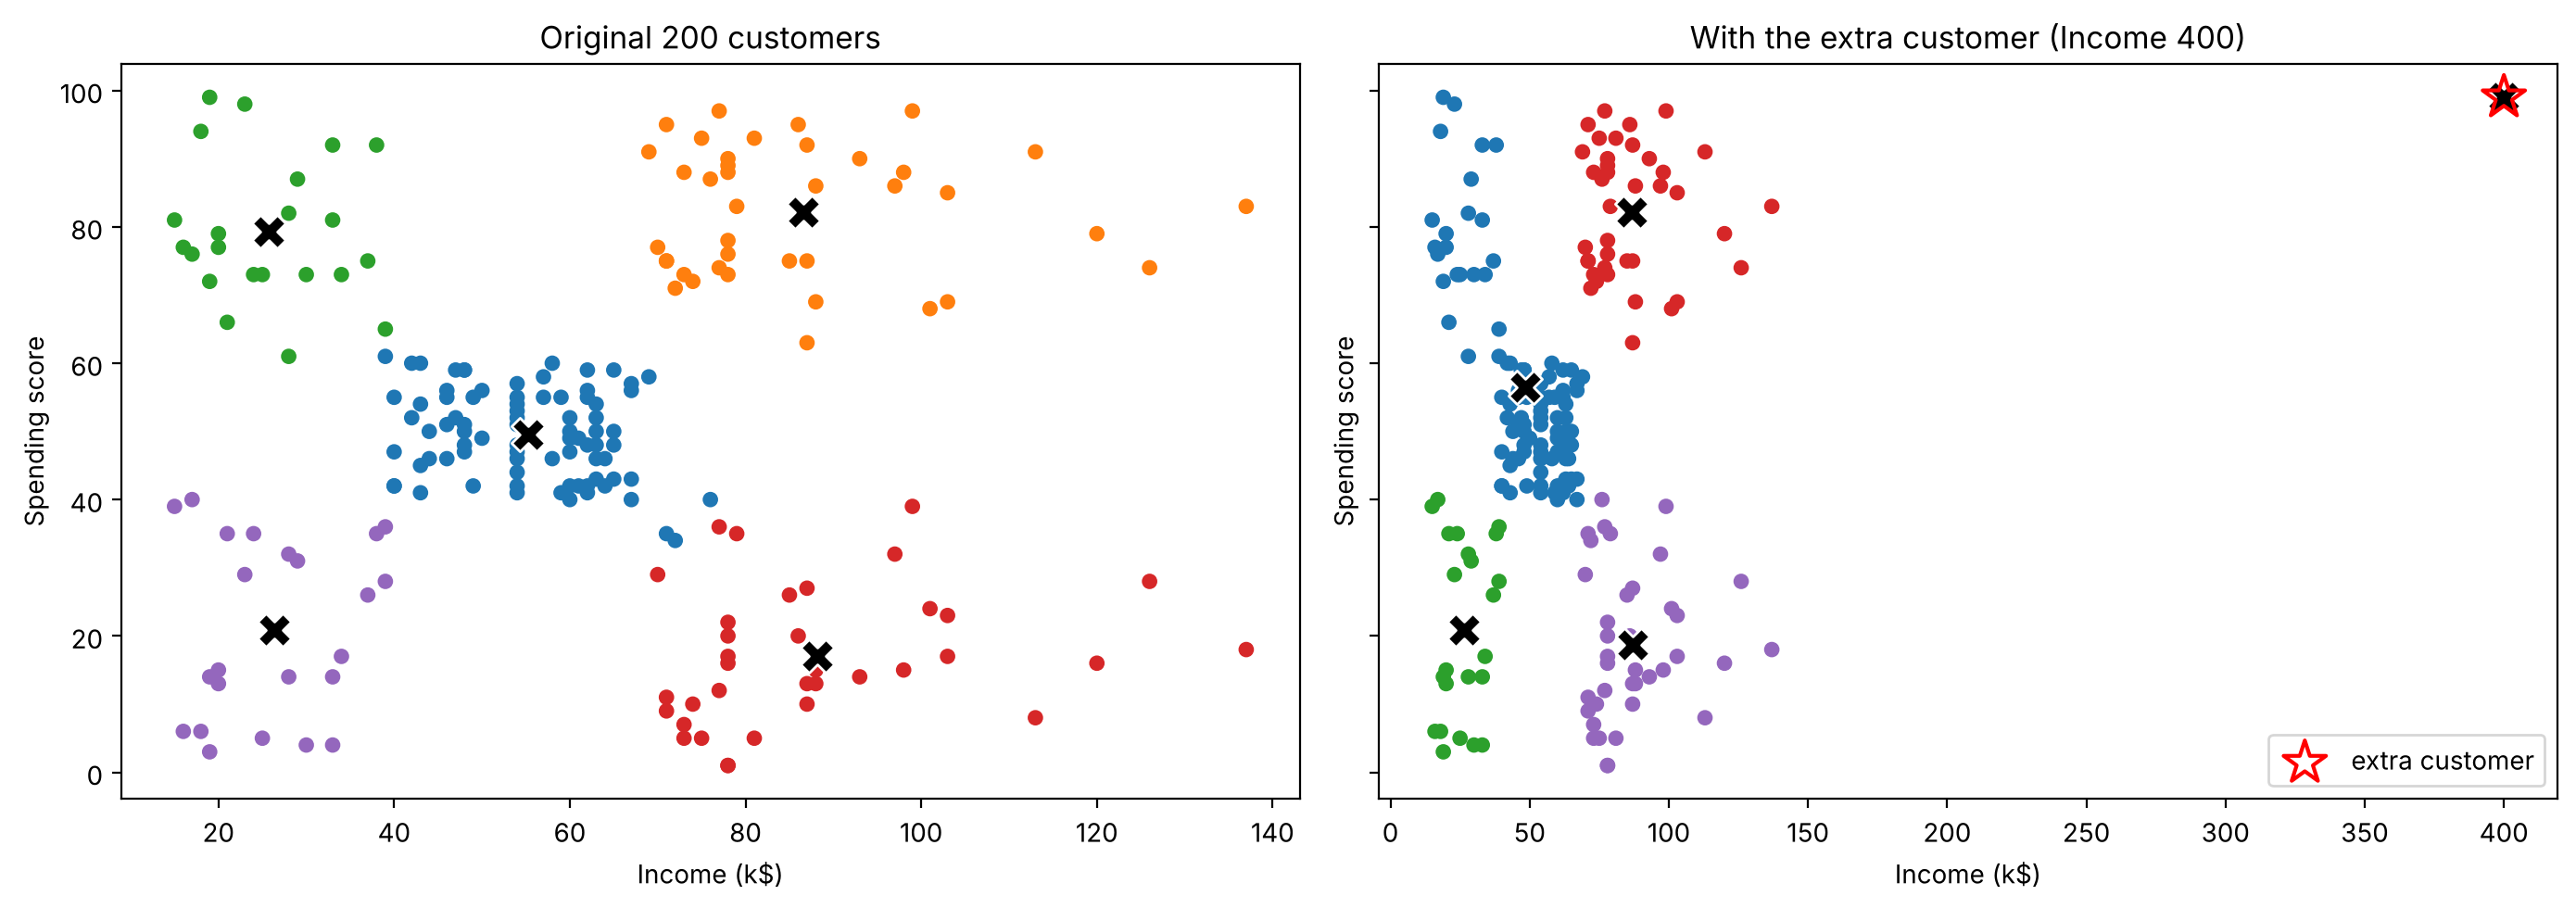

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

ax[0].scatter(X2[:, 0], X2[:, 1], c=km_base.labels_, cmap="tab10", vmin=0, vmax=9, s=25)
ax[0].scatter(km_base.cluster_centers_[:, 0], km_base.cluster_centers_[:, 1], c="black", marker="X", s=170, edgecolor="white")
ax[0].set_title("Original 200 customers")

ax[1].scatter(X_out[:, 0], X_out[:, 1], c=km_out.labels_, cmap="tab10", vmin=0, vmax=9, s=25)
ax[1].scatter(km_out.cluster_centers_[:, 0], km_out.cluster_centers_[:, 1], c="black", marker="X", s=170, edgecolor="white")
ax[1].scatter(400, 99, marker="*", s=300, facecolor="none", edgecolor="red", linewidth=1.5, label="extra customer")
ax[1].set_title("With the extra customer (Income 400)")
ax[1].legend(loc="lower right")

for a in ax:
    a.set_xlabel("Income (k$)")
    a.set_ylabel("Spending score")
plt.tight_layout()
plt.show()

**Interpretation:** One extra customer with Income 400 takes a whole cluster for itself (size 1, centroid at (400, 99)). The real customers then have only 4 centroids. Without it the sizes were 22 (low income / high spending), 23, 81, 39 and 35. With it the low income / high spending group is gone: it is merged into the big middle cluster, which grows to 100 customers and moves from (55.3, 49.5) to (48.3, 56.5), and the high income / low spending cluster grows from 35 to 38. Only the 23-customer and 39-customer clusters stay the same. The ARI on the original 200 customers is 0.7532.

### Task 5.2 — Catch it and repair

In [34]:
# distances from the model fitted on the original 200
dist = pd.Series(km_base.transform(X2).min(axis=1))
d_extra = km_base.transform(extra).min()

threshold = dist.mean() + 3 * dist.std()
flag_real = dist > threshold

print("mean distance:", round(dist.mean(), 2), "| std:", round(dist.std(), 2))
print("threshold (mean + 3 std):", round(threshold, 2))
print("distance of the extra customer:", round(d_extra, 2))
print("extra customer flagged:", d_extra > threshold)
print("real customers flagged:", flag_real.sum())

mean distance: 13.02 | std: 7.28
threshold (mean + 3 std): 34.86
distance of the extra customer: 313.92
extra customer flagged: True
real customers flagged: 4


In [35]:
far = df.copy()
far["Cluster"] = km_base.labels_
far["Distance"] = dist.round(2)
far[["CustomerID", "Age", "Income", "Spending", "Cluster", "Distance"]].sort_values("Distance", ascending=False).head(5).reset_index(drop=True)

,CustomerID,Age,Income,Spending,Cluster,Distance
0,200,30,137,83,1,50.47
1,199,32,137,18,3,48.81
2,198,32,126,74,1,40.29
3,197,45,126,28,3,39.34
4,196,35,120,79,1,33.61


In [36]:
far[flag_real][["CustomerID", "Gender", "Age", "Income", "Spending", "Cluster", "Distance"]].sort_values("Distance", ascending=False).reset_index(drop=True)

,CustomerID,Gender,Age,Income,Spending,Cluster,Distance
0,200,Male,30,137,83,1,50.47
1,199,Male,32,137,18,3,48.81
2,198,Male,32,126,74,1,40.29
3,197,Female,45,126,28,3,39.34


In [37]:
# remove every flagged point (the extra one + the flagged real ones) and refit
dist_all = km_base.transform(X_out).min(axis=1)
flag_all = dist_all > threshold
print("points removed:", flag_all.sum(), "out of", len(X_out))

km_clean = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X_out[~flag_all])
print("cluster sizes of the repaired model:", np.bincount(km_clean.labels_))

# predict for all 200 original customers and compare with the original model
pred_clean = km_clean.predict(X2)
print("cluster sizes when predicting all 200:", np.bincount(pred_clean, minlength=5))
print("ARI vs original model:", round(adjusted_rand_score(km_base.labels_, pred_clean), 4))

points removed: 5 out of 201
cluster sizes of the repaired model: [80 34 23 37 22]
cluster sizes when predicting all 200: [80 36 23 39 22]
ARI vs original model: 0.9847


**Interpretation:** For the 200 real customers the distance to the nearest centroid has mean 13.02 and std 7.28, so the mean + 3 std threshold is 34.86. The extra customer has distance 313.92, about 9 times the threshold, so it is flagged. The rule also flags 4 real customers (IDs 200, 199, 198 and 197). They are the four customers with the highest incomes in the data (137, 137, 126, 126), at the far right edge of their clusters, so they are real rich customers and not mistakes (customers 200 and 198 spend a lot, 199 and 197 spend little). I removed all 5 flagged points and refitted with K=5: the cluster sizes are [80, 34, 23, 37, 22], and when I predict the 200 original customers they are [80, 36, 23, 39, 22] with ARI 0.9847 against the original model, so the repair works.

### Questions for Part 5

**(a)** The extreme customer took one centroid for itself, so the 5 real groups had to share 4 centroids. The low income / high spending group (22 customers, centroid (25.7, 79.4)) disappeared and merged into the middle group, which grew to 100 customers and moved to (48.3, 56.5). The high income / low spending group went from 35 to 38. The low/low (23) and high/high (39) groups were not affected. ARI on the original 200 is 0.7532.

**(b)** The rule detected it very well: distance 313.92 against a threshold of 34.86. It also flagged 4 real customers (IDs 197 to 200). They are not mistakes. They are the 4 highest incomes in the data (137k and 126k) and sit at the far edge of their clusters, so they are worth looking at as possible VIP customers.

**(c)** Two ways: (1) check whether it is a data error and remove or fix it, (2) limit its effect by capping (clipping) the value or using a log transform, or use a method that is not so sensitive like K-Medoids or DBSCAN. The risk of simply deleting is that a real and important customer can be removed (like the 4 rich customers here), and then the model does not know how to handle similar customers in the future.

## Part 6 — From Clusters to Customer Segments

### Task 6.1 — Profile and name the segments

In [38]:
df["Cluster"] = km_base.labels_

profile = df.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Age=("Age", "mean"),
    Income=("Income", "mean"),
    Spending=("Spending", "mean"),
    Pct_Female=("Gender", lambda g: 100 * (g == "Female").mean()),
).round(1).sort_values("Income")
profile

,Customers,Age,Income,Spending,Pct_Female
Cluster,,,,,
2,22,25.3,25.7,79.4,59.1
4,23,45.2,26.3,20.9,60.9
0,81,42.7,55.3,49.5,59.3
1,39,32.7,86.5,82.1,53.8
3,35,41.1,88.2,17.1,45.7


In [39]:
def income_level(v):
    if v < 40:
        return "Low"
    if v >= 70:
        return "High"
    return "Mid"


def spend_level(v):
    if v < 35:
        return "Low"
    if v >= 65:
        return "High"
    return "Mid"


# name each cluster from its average income and spending
seg_names = {}
for k, row in profile.iterrows():
    seg_names[k] = income_level(row["Income"]) + " income / " + spend_level(row["Spending"]) + " spending"

df["Segment"] = df["Cluster"].map(seg_names)
print("names are all different:", len(set(seg_names.values())) == 5)
print()
print(df["Segment"].value_counts())

names are all different: True

Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64


**Interpretation:** The profile table (sorted by income) shows 5 clear customer types. The rule gives 5 different names, and the segment sizes are 81 (Mid / Mid), 39 (High / High), 35 (High income / Low spending), 23 (Low / Low) and 22 (Low income / High spending). The Mid / Mid group is the biggest and Low income / High spending is the smallest, and that smallest group is also the youngest (mean age 25.3).

### Task 6.2 — Does Gender matter? Does Age matter?

In [40]:
gender_seg = pd.crosstab(df["Segment"], df["Gender"], normalize="index") * 100
print("% of each gender inside every segment")
print(gender_seg.round(1))
print()
print("overall % female:", round(100 * (df["Gender"] == "Female").mean(), 1))

% of each gender inside every segment
Gender                       Female  Male
Segment                                  
High income / High spending    53.8  46.2
High income / Low spending     45.7  54.3
Low income / High spending     59.1  40.9
Low income / Low spending      60.9  39.1
Mid income / Mid spending      59.3  40.7

overall % female: 56.0


In [41]:
X3 = StandardScaler().fit_transform(df[["Age", "Income", "Spending"]])

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X3)
    rows.append([k, km.inertia_, silhouette_score(X3, km.labels_)])

res3 = pd.DataFrame(rows, columns=["K", "Inertia", "Silhouette"])
print(res3.round(4).to_string(index=False))
print()
print("best K by silhouette:", int(res3.loc[res3["Silhouette"].idxmax(), "K"]))

 K  Inertia  Silhouette
 2 389.3862      0.3355
 3 295.2122      0.3578
 4 205.2251      0.4040
 5 168.2476      0.4166
 6 133.8684      0.4284
 7 117.0116      0.4172
 8 103.8733      0.4082

best K by silhouette: 6


**Interpretation:** Overall 56.0% of the customers are women. Inside the segments it goes from 45.7% (High income / Low spending) to 60.9% (Low / Low), with 53.8% in High / High, 59.1% in Low income / High spending and 59.3% in Mid / Mid. The differences are small (at most about 10 points from the overall number, in groups of 22 to 35 customers), so Gender does not separate the segments. For the three scaled features the silhouette for K = 2 to 8 is 0.3355, 0.3578, 0.4040, 0.4166, 0.4284, 0.4172, 0.4082, so the best is K=6.

### Task 6.3 — A three-feature alternative

In [42]:
best_k3 = int(res3.loc[res3["Silhouette"].idxmax(), "K"])
km3 = KMeans(n_clusters=best_k3, n_init=10, random_state=SEED).fit(X3)

df3 = df[["Age", "Income", "Spending"]].copy()
df3["Cluster3"] = km3.labels_
profile3 = df3.groupby("Cluster3").agg(
    Size=("Age", "count"),
    Age=("Age", "mean"),
    Income=("Income", "mean"),
    Spending=("Spending", "mean"),
).round(1).sort_values("Age")
print("K =", best_k3)
print(profile3)
print()
print("ARI vs the 2-feature K=5 segmentation:", round(adjusted_rand_score(df["Cluster"], km3.labels_), 4))

K = 6
          Size   Age  Income  Spending
Cluster3                              
4           23  25.0    25.3      77.6
1           39  26.8    57.1      48.1
3           39  32.7    86.5      82.1
2           33  41.9    88.9      17.0
5           21  45.5    26.3      19.4
0           45  56.3    54.3      49.1

ARI vs the 2-feature K=5 segmentation: 0.7002


**Interpretation:** With Age, Income and Spending (scaled) and K=6 the profile is: age 25.0 / income 25.3 / spending 77.6 (23 customers), age 26.8 / 57.1 / 48.1 (39), age 32.7 / 86.5 / 82.1 (39), age 41.9 / 88.9 / 17.0 (33), age 45.5 / 26.3 / 19.4 (21) and age 56.3 / 54.3 / 49.1 (45). The ARI with the 2-feature K=5 segmentation is 0.7002. Four of the old groups are still easy to find. The main change is that the Mid / Mid group (81 customers) is split by age into a young group (mean age 26.8) and an older group (mean age 56.3).

### Questions for Part 6

**(a)** Segment names and actions (numbers from the profile table):
- **Mid income / Mid spending (81 customers, income 55.3, spending 49.5): "Everyday shoppers".** Give loyalty points and bundle offers to raise their basket size.
- **High income / High spending (39, income 86.5, spending 82.1, age 32.7): "VIPs".** Give early access to new products and a premium membership with personal invitations.
- **High income / Low spending (35, income 88.2, spending 17.1): "Rich but not buying".** Send personal offers for premium products and ask them why they shop less here.
- **Low income / High spending (22, income 25.7, spending 79.4, age 25.3): "Young enthusiasts".** Give student/young discounts and small trendy items, but not expensive credit offers.
- **Low income / Low spending (23, income 26.3, spending 20.9, age 45.2): "Budget savers".** Use cheap channels like clearance and discount-day messages, and do not spend much marketing money on them.

**(b)** The most valuable now is High income / High spending (39 customers with income 86.5 and spending score 82.1). The biggest opportunity is High income / Low spending (35 customers): their income is 88.2, nearly the same as the VIPs, but their spending score is only 17.1, so moving them even to the middle would add a lot.

**(c)** Not really. Women are 56.0% overall and between 45.7% and 60.9% inside the segments, so there is no segment that is clearly male or female. High income / Low spending has the lowest share of women (45.7%) and it is the only segment where men are more than half, but the difference is small.

**(d)** Adding Age changes the story a little: K=6 is best with silhouette 0.4284, and it splits the Mid / Mid group into young (mean age 26.8) and older (56.3) customers while the other groups stay almost the same (ARI 0.7002 with the first segmentation). The silhouette of 0.4284 cannot be compared with 0.5539 because the feature sets are different. I would present the 2-feature K=5 segmentation as the main one because it is easier to explain, has the clearest groups and fits the scatter plot, and I would mention the age split of the middle group as an extra idea for later.

## Part 7 — Final Output and Wrap-Up

### Task 7.1 — Save the segments

In [43]:
out = df[["CustomerID", "Age", "Gender", "Income", "Spending", "Cluster", "Segment"]]
out.to_csv("customer_segments.csv", index=False)

print("saved", out.shape[0], "rows")
print(out["Segment"].value_counts())
out.head()

saved 200 rows
Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64


,CustomerID,Age,Gender,Income,Spending,Cluster,Segment
0,1,19,Male,15,39,4,Low income / Low spending
1,2,21,Male,15,81,2,Low income / High spending
2,3,20,Female,16,6,4,Low income / Low spending
3,4,23,Female,16,77,2,Low income / High spending
4,5,31,Female,17,40,4,Low income / Low spending


**Interpretation:** `customer_segments.csv` is saved with 200 rows and the columns CustomerID, Age, Gender, Income, Spending, Cluster and Segment. The segment sizes are 81, 39, 35, 23 and 22, and they add up to 200.

### Executive Summary
- I chose K=5 for Income and Spending: the elbow bends at 5 (inertia drops by 29231 from K=4 to 5 but only 7215 from 5 to 6) and the silhouette is highest at K=5 (0.5539).
- The segments are Mid / Mid (81), High / High (39), High income / Low spending (35), Low / Low (23) and Low income / High spending (22).
- Actions: loyalty bundles for the Mid / Mid group, VIP early access for High / High, personal premium offers for High income / Low spending, young discounts for Low income / High spending and low-cost clearance messages for Low / Low.
- I used n_init=10 with k-means++, which gave the best inertia (44448.5) in all 30 seeds, while a single random start only reached it in 33.3% of runs.
- Scaling matters: Income in dollars made the clusters depend only on Income (ARI 1.0 with an Income-only clustering). I used the original k$ for Income and Spending because both are on a similar scale. One customer with Income 400 destroyed a real group and was caught by the mean + 3 std distance rule, which also flagged 4 real high-income customers that I kept.
- Limitation: the segments use only Income and Spending score from 200 customers, and K-Means finds round groups, so the result may change with more customers or features (for example, Age splits the middle group).

### Questions for Part 7

**(a)** The most surprising result was the Wine silhouette: the raw clustering had a higher silhouette (0.5711) than the scaled one (0.2849), even though its ARI against the true cultivars was much worse (0.3711 vs 0.8975). Also, one single customer was enough to remove a whole group of 22 customers.

**(b)** I would compare K-Means with a Gaussian mixture or DBSCAN on the same data, check how stable the 5 segments are with bootstrap samples, and test whether adding a purchase-frequency feature (if available) changes the segments.